# Поиск оптимальной стратегии методом Монте-Карло

Реализуем **метод Монте-Карло** для поиска оптимальной стратегии с помощью **обобщённой итерации по 𝜀-жадным стратегиям** с GLIE, то есть с постепенным убыванием 𝜀. Этот метод базируется на вычислении оценки Q-функции. Ранее, мы использовали "табличного" агента для оценки стратегии по методу Монте-Карло. Этот агент приближал V-функцию. 

Сформируем абстрактный класс "табличного" агента, который хранит Q-функцию и способен взаимодействовать со средой по 𝜀-жадной стратегии относительно Q-функции. Алгоритмы обучения такого агента будем реализовывать в потомках этого класса.

Программно Q-функцию удобно реализовать как словарь `defaultdict`. Структура `defaultdict` позволяет заполнять словарь по ходу взаимодействия со средой, не формируя заранее множество возможных ключей. Это моделирует ситуацию, когда агнет заранее ничего не знает о среде. Ключами будут состояния `s`, а значениями являются вектора, содержащие числа `Q[s][a]` для всех возможных действий. Число, хранящееся в `Q[s][a]`, и является оценкой ценности ценности действия `a` в состоянии `s`.

Базовые функции:

    reset()       - сброс значений Q-функции;
    update_Q()    - обновления значений Q(s,a) в сторону цели обновления goal;
    get_action()  - выбор действий по eps-жадной стратегии относительно текущей Q-функции;
    best_action() - выбор жадного действия относительно текущей Q-функции;
    play()        - запуск симуляции взаимодействия обученного агента со средой.

Добавим также функции `save_Q` и `load_Q` для сохранения и подгрузки значений Q-функции. И метод `get_Q` для получения значений Q-функции внешними методами.

Также агент содержит абстрактный метод `learn()`, который необходимо реализовать в потомках на основе выбранного алгоритма обучения агента.

Поскольку стратегия выбора действий зафиксирована, то поле `policy`, отвечавшее ранее за хранение стратении, теперь не требуется.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
import pickle

from abc import ABC, abstractmethod
from collections import defaultdict


class QTableAgent(ABC):
    def __init__(self, env, eps = 0.1, alpha = 0.1):
        self.nA = env.action_space.n # число действий
        self.N = defaultdict(lambda: np.zeros(self.nA))
        # заполняемая таблица значений Q-функции, хранящая ценности пар состояние-действие
        self.Q = defaultdict(lambda: np.zeros(self.nA))
    
        self.eps = eps   
        self.alpha = alpha

    # выбор eps-жадного действия        
    def reset(self):
        self.N = defaultdict(lambda: np.zeros(self.nA))
        self.Q = defaultdict(lambda: np.zeros(self.nA))

    # выбор eps-жадного действия        
    def get_action(self, state):
        if np.random.rand() < self.eps:
            return np.random.choice(self.nA)
        return self.best_action(state)
    
    # выбор жадного действия        
    def best_action(self, state):
        return np.argmax(self.Q[state])

    def get_Q(self, state, act):
        return self.Q[state][act]

    def update_Q(self, state, act, goal):
        # обновление оценки по методу выборочного среднего или с постоянным шагом обновления
        if self.alpha is None:
            self.N[state][act] += 1
            self.Q[state][act] += (goal - self.Q[state][act])/self.N[state][act]
        else:
            self.Q[state][act] += self.alpha*(goal - self.Q[state][act])

    @abstractmethod
    def learn(self):
        """Метод обучения"""
        pass

    def play(self, env, n_episodes):
        """Оценка качества обученного агента. """
        for _ in tqdm(range(n_episodes)):
            state, _ = env.reset()
            while True:
                # выбираем лучшие действия
                action = self.best_action(state)
                state, reward, terminated, truncated, _ = env.step(action)
                if terminated or truncated:
                    break

    def save_Q(self, name):
        os.makedirs('savedModels', exist_ok=True)
        with open('savedModels/TableAgent_'+name+".pkl",'wb') as f:
            pickle.dump(dict(self.Q), f)
        return 'savedModels/TableAgent_'+name+".pkl"
        
    def load_Q(self, name):
        self.reset()
        with open(name, 'rb') as f:
            loaded_data = pickle.load(f)
            self.Q = defaultdict(lambda: np.zeros(self.nA), loaded_data) 

Сформируем класс агента `MC_Agent`, обучающегося по методу Монте-Карло, и реализуем методы:

    learn()            - алгоритм обучения по методу Монте-Карло
    generate_episode() - генерация эпизода, что необходимо для обучения

Для значений гиперпараметров сформируем специальный `dataclass`.

Для демонстрации результатов обучения напишем метод, извлекающий жадную стратегию относительно текущих оценок Q-функции в виде словаря.

In [3]:
from dataclasses import dataclass

@dataclass
class ConfigMC:
    gamma: float = 0.99
    eps_start: float = 1.0
    eps_decay: float = 0.999
    eps_min: float = 0.01
    alpha_start: float = None
    alpha_decay: float = 1.00
    alpha_min: float = 0.01
    first_visit: bool = False

class MC_Agent(QTableAgent): 
    def __init__(self, env, config = None):
        super().__init__(env)
        if config is None:
            self.config = ConfigMC()
        else:
            self.config = config
            
        self.env = env
        self.alpha = self.config.alpha_start
        self.eps = self.config.eps_start
        self.gamma = self.config.gamma

    def generate_episode(self):    
        episode = [] #список для хранения траектории
        state, _ = self.env.reset()    
        while True:
            action = self.get_action(state)
            next_state, reward, terminated, truncated, _ = self.env.step(action)      
            episode.append((state, action, reward))
            state = next_state
            if terminated or truncated:
                    break
        return episode

    def learn(self, n_episodes = 1000, restart = True):
        if restart == True:
            self.alpha = self.config.alpha_start
            self.eps = self.config.eps_start 
            self.reset()

        # ===== работа алгоритма обучения  =====
        for _ in tqdm(range(n_episodes)):
            # генерация траектории по eps-жадной стратегии относительно Q
            episode = self.generate_episode()       
            # если МК первого посещения, то выделим из эпизода все пары состояние-действие
            if self.config.first_visit:
                episode_states, episode_acts, _ = zip(*episode)
                s_a_pairs = list(zip(episode_states,episode_acts))
    
            # подсчёт доходов и обновление оценок
            G = 0
            ep_length = len(episode)
            for t in range(ep_length-1, -1, -1):
                s, a, r = episode[t]
                G = self.gamma*G + r
                if self.config.first_visit:
                    if (s, a) not in s_a_pairs[:t]:
                        self.update_Q(s,a,G)
                else:                    
                    self.update_Q(s,a,G)
                    
            # уменьшение доли шагов исследования
            self.eps = max(self.eps * self.config.eps_decay, self.config.eps_min)         
            if self.alpha is not None:
                self.alpha = max(self.alpha * self.config.alpha_decay, self.config.alpha_min)   
                

    def get_greedy_policy(self):
        # Получение жадной стратегии относительно текущей Q-функции
        greedy_policy = dict((state, np.argmax(Qvalues)) for state, Qvalues in self.Q.items())
        return greedy_policy

### Пример 1

Рассмотрим задачу о замерзшем озере `FrozenLake-v1` с детеминированными переходами и найдём оптимальную стратегию методом Монте-Карло.
Проведём, например, 2000 симуляций, выведем значения функции ценности состояний.

In [3]:
import gymnasium as gym
env = gym.make("FrozenLake-v1", is_slippery = False)
agent = MC_Agent(env)

In [4]:
agent.learn(2000)

100%|██████████| 2000/2000 [00:00<00:00, 5424.33it/s]


In [5]:
V_opt = dict((state,np.max(Qvalue)) for state, Qvalue in agent.Q.items())
V_list = np.zeros((4,4))
for i in range(4):
    for j in range(4):
        pos = 4*i+j
        if pos in V_opt.keys():
            V_list[i,j] = V_opt[pos]
    
V_list

array([[0.50764704, 0.34228079, 0.41679073, 0.08100889],
       [0.63001748, 0.        , 0.69515248, 0.        ],
       [0.73772427, 0.83780877, 0.95212841, 0.        ],
       [0.        , 0.90563138, 1.        , 0.        ]])

Выведем построенную стратегию.

In [6]:
policy = agent.get_greedy_policy()

action_labels = {0:"←", 1:"↓", 2: "→", 3:"↑"}
optimal_actions=[0]*16
for i in range(4):
    for j in range(4):
        pos = 4*i+j
        if pos in policy.keys():
            optimal_actions[4*i+j] = action_labels[policy[4*i+j]]
        else:
            optimal_actions[4*i+j] = "*" 
optimal_actions[15] = "*" 

print("Стратегия:\n",np.array(optimal_actions).reshape((4,4)))

Стратегия:
 [['↓' '→' '↓' '←']
 ['↓' '*' '↓' '*']
 ['→' '→' '↓' '*']
 ['*' '→' '→' '*']]


Симуляция на 2000 эпизодов нашла оптимальную стратегию, хотя не все значения Q-функции сошлись к оптимальным значениям. 

Большее число эпизодов позволит гарантированно добраться и до верных значений Q-функции.

Например, запустим обучения с фиксированным шагом обучения, обучение на 50000 эпизодах.

In [7]:
import gymnasium as gym
env = gym.make("FrozenLake-v1", is_slippery = False)
agent = MC_Agent(env)
agent.config.alpha_start = 0.05

agent.learn(50000)

100%|██████████| 50000/50000 [00:05<00:00, 9623.28it/s] 


In [8]:
V_opt = dict((state,np.max(Qvalue)) for state, Qvalue in agent.Q.items())
V_list = np.zeros((4,4))
for i in range(4):
    for j in range(4):
        pos = 4*i+j
        if pos in V_opt.keys():
            V_list[i,j] = V_opt[pos]
    
V_list

array([[0.87499477, 0.86919333, 0.89271345, 0.869677  ],
       [0.8838331 , 0.        , 0.93808222, 0.        ],
       [0.93249441, 0.9798053 , 0.98997109, 0.        ],
       [0.        , 0.98999988, 1.        , 0.        ]])

In [9]:
policy = agent.get_greedy_policy()

action_labels = {0:"←", 1:"↓", 2: "→", 3:"↑"}
optimal_actions=[0]*16
for i in range(4):
    for j in range(4):
        pos = 4*i+j
        if pos in policy.keys():
            optimal_actions[4*i+j] = action_labels[policy[4*i+j]]
        else:
            optimal_actions[4*i+j] = "*" 
optimal_actions[15] = "*" 

print("Стратегия:\n",np.array(optimal_actions).reshape((4,4)))

Стратегия:
 [['↓' '←' '↓' '←']
 ['↓' '*' '↓' '*']
 ['→' '→' '↓' '*']
 ['*' '→' '→' '*']]


### Пример 2

Рассмотрим работу методов Монте-Карло для поиска оптимальной стратегии на примере среды **Blackjack**. Запустим обучение на 500000 эпизодах.

In [13]:
import gymnasium as gym

env = gym.make('Blackjack-v1')

config = ConfigMC(gamma = 1.0,
        eps_start = 1.0, 
        eps_decay = 0.9999, 
        eps_min = 0.001,                
        alpha_start = None, 
        alpha_decay = 0.99, 
        alpha_min = 0.01,
        first_visit = False
)

agent = MC_Agent(env, config)

In [14]:
agent.learn(n_episodes = 100000)

100%|██████████| 100000/100000 [00:13<00:00, 7579.95it/s]


Построим график найденной V-функции. Будем считать, что найденная Q-функция оптимальна, тогда V-функция получается из Q-функции следующим образом:

$$
V(s) = \max_a Q(s,a)
$$

In [15]:
import matplotlib.pyplot as plt

# функция для построения графика
def get_figure(V, usable_ace, ax):
    # создание списка аргументов
    x_range = np.arange(12, 22)
    y_range = np.arange(2, 11)
    X, Y = np.meshgrid(x_range, y_range)
    all_x_y = zip(np.ravel(X), np.ravel(Y))
    # получаем значения по оси Oz 
    Z = np.array([V[x, y, usable_ace] for x,y in all_x_y])
    Z = Z.reshape(X.shape)
    # строим 3D график
    surf = ax.plot_surface(X, Y, Z, rstride=1, cstride=1, cmap=plt.cm.coolwarm, vmin=-1.0, vmax=1.0)
    ax.set_xlabel('Сумма очков игрока')
    ax.set_ylabel('Очки карты дилера')
    ax.set_zlabel('Значение ценности')
    #установка угла зрения на график
    ax.view_init(30, -135)

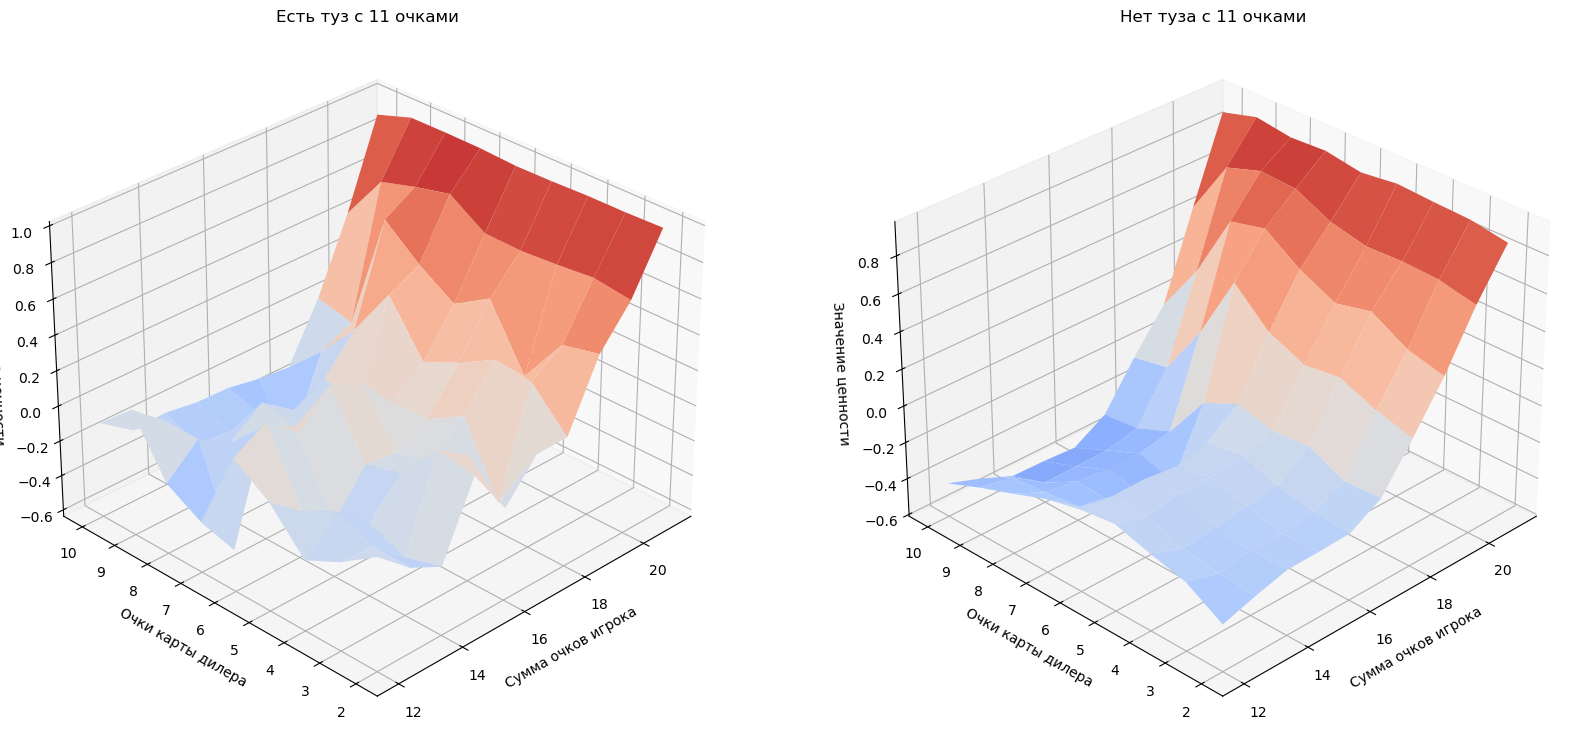

In [16]:
V_opt = defaultdict(lambda: 0)
for state, Qvalue in agent.Q.items():
    V_opt[state]  = np.max(Qvalue)


fig = plt.figure(figsize=(20, 20))
ax = fig.add_subplot(121, projection='3d')
ax.set_title('Есть туз с 11 очками')
get_figure(V_opt, True, ax)
ax = fig.add_subplot(122, projection='3d')
ax.set_title('Нет туза с 11 очками')
get_figure(V_opt, False, ax)

Проведём также симуляцию на 10000 эпизодах, чтобы выявить среднее число выигранных игр и средний доход.

In [19]:
n_episodes = 10000
env = gym.make('Blackjack-v1')
env = gym.wrappers.RecordEpisodeStatistics(env, buffer_length=n_episodes)

agent.play(env, n_episodes)

100%|██████████| 10000/10000 [00:01<00:00, 7846.15it/s]


In [20]:
print('Процент победных эпизодов: ', np.round(env.return_queue.count(1.0)/n_episodes*100,2))
print('Процент проигранных эпизодов: ', np.round(env.return_queue.count(-1.0)/n_episodes*100,2))
print('Процент эпизодов в ничью: ', np.round(env.return_queue.count(0.0)/n_episodes*100,2))
print('Средний доход:', np.mean(env.return_queue))

Процент победных эпизодов:  41.95
Процент проигранных эпизодов:  50.15
Процент эпизодов в ничью:  7.9
Средний доход: -0.082


Как видно, средний выигрыш при найденной стратегии не превосходит 0. 

Визуализируем также графически стратегию. Для этого используем следующий код.

In [21]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
def plot_policy(policy):

    def get_Z(x, y, usable_ace):
        if (x,y,usable_ace) in policy:
            return policy[x,y,usable_ace]
        else:
            return 1

    def get_figure(usable_ace, ax):
        x_range = np.arange(12, 22)
        y_range = np.arange(10, 0, -1)
        X, Y = np.meshgrid(x_range, y_range)
        Z = np.array([[get_Z(x,y,usable_ace) for x in x_range] for y in y_range])
        surf = ax.imshow(Z, cmap=plt.get_cmap('Pastel2', 2), vmin=0, vmax=1, extent=[11.5, 21.5, 0.5, 10.5])
        plt.xticks(x_range)
        plt.yticks(y_range)
        plt.gca().invert_yaxis()
        ax.set_xlabel('Очки агента')
        ax.set_ylabel('Карта дилера')
        ax.grid(color='w', linestyle='-', linewidth=1)
        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="5%", pad=0.1)
        cbar = plt.colorbar(surf, ticks=[0,1], cax=cax)
        cbar.ax.set_yticklabels(['0 (STICK)','1 (HIT)'])
            
    fig = plt.figure(figsize=(15, 15))
    ax = fig.add_subplot(121)
    ax.set_title('Есть туз с 11 очками')
    get_figure(True, ax)
    ax = fig.add_subplot(122)
    ax.set_title('Нет туза с 11 очками')
    get_figure(False, ax)
    plt.show()

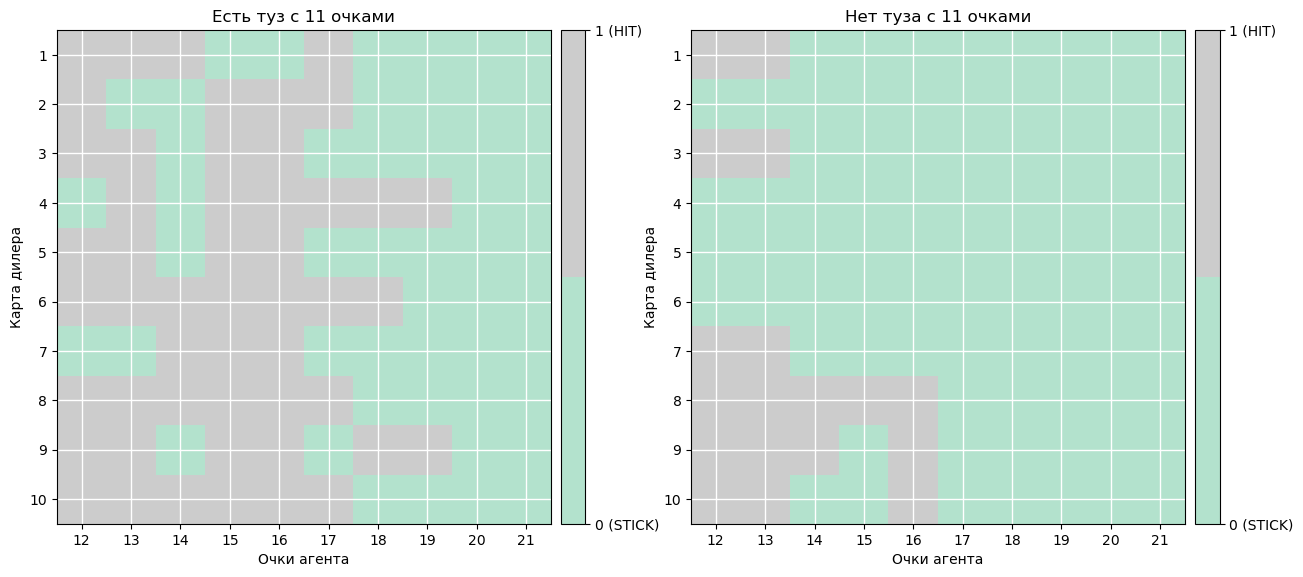

In [22]:
policy = agent.get_greedy_policy()
plot_policy(policy)

Можно увеличить число эпизодов обучения, чтобы получить стратегию, известную как оптимальная.

In [24]:
import gymnasium as gym

env = gym.make('Blackjack-v1')

config = ConfigMC(gamma = 1.0,
        eps_start = 1.0, 
         eps_decay= 0.99995, 
        eps_min = 0.0005,                
        alpha_start = 0.001, 
        alpha_decay = 1.0, 
        alpha_min = 0.001,
        first_visit = False
)

agent_best = MC_Agent(env, config = config)

In [25]:
agent_best.learn(5000000)

100%|██████████| 5000000/5000000 [11:30<00:00, 7244.09it/s]


Сохраним эту найденную Q-функцию.

In [28]:
agent_best.save_Q('MC_Blackjack_5M')

'savedModels/TableAgent_MC_Blackjack_5M.pkl'

Эту стратегию можно подгрузить из файла.

In [29]:
agent_best = MC_Agent(env)
agent_best.load_Q('savedModels/TableAgent_MC_Blackjack_5M.pkl')

Визуализируем полученную V-функцию и соответствующую стратегию.

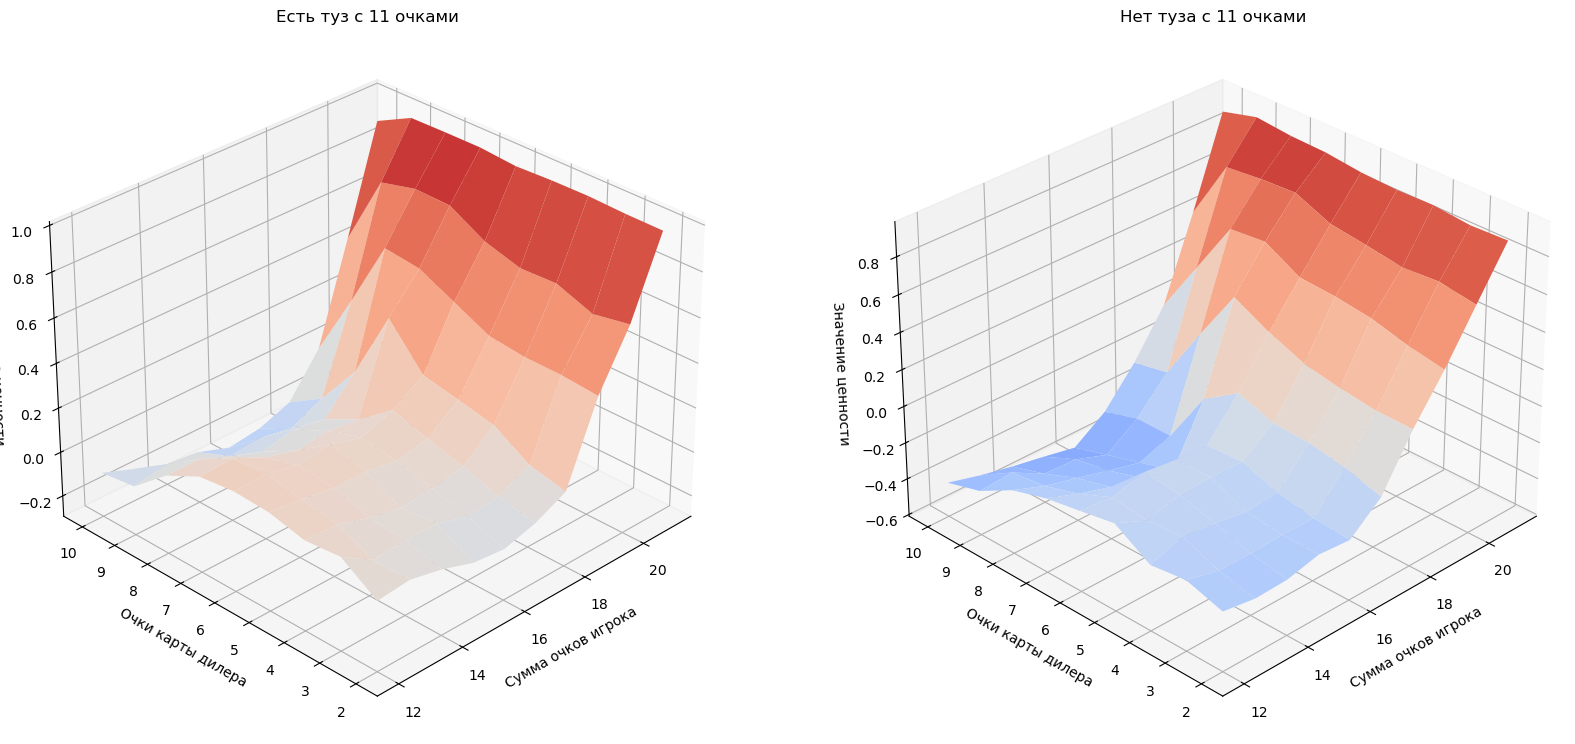

In [30]:
import matplotlib.pyplot as plt
# получим V-функцию
V_opt = dict((k,np.max(v)) for k, v in agent_best.Q.items())

fig = plt.figure(figsize=(20, 20))
ax = fig.add_subplot(121, projection='3d')
ax.set_title('Есть туз с 11 очками')
get_figure(V_opt, True, ax)
ax = fig.add_subplot(122, projection='3d')
ax.set_title('Нет туза с 11 очками')
get_figure(V_opt, False, ax)

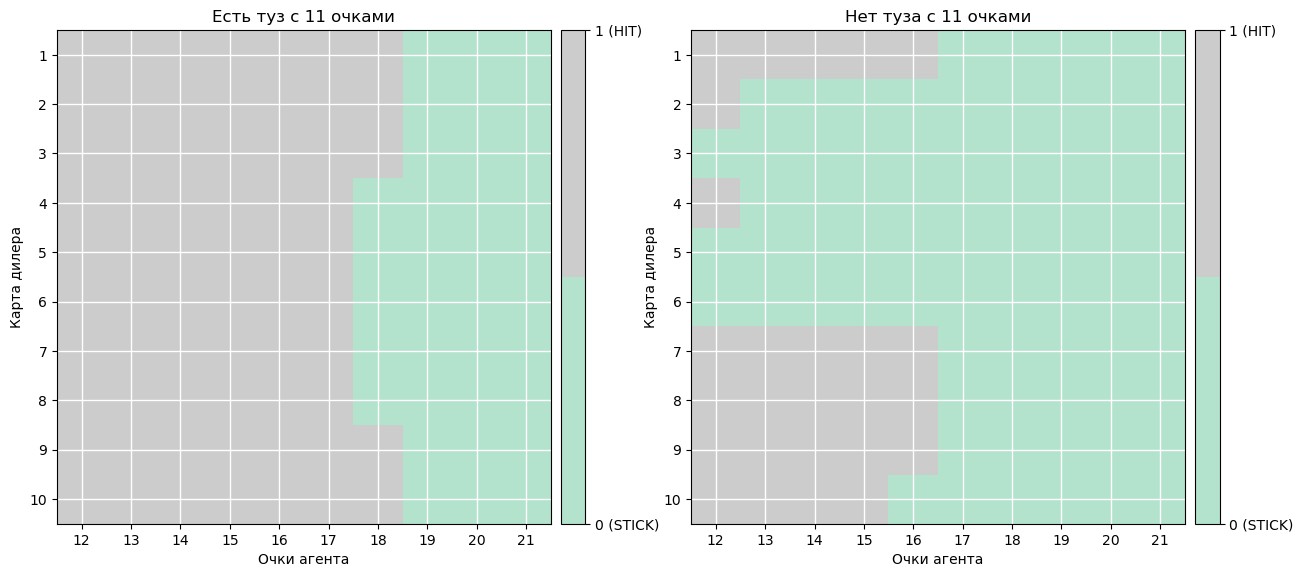

In [31]:
policy = agent_best.get_greedy_policy()
plot_policy(policy)

In [36]:
n_episodes = 10000
env = gym.make('Blackjack-v1')
env = gym.wrappers.RecordEpisodeStatistics(env, buffer_length=n_episodes)

agent_best.play(env, n_episodes)

print('Процент победных эпизодов: ', np.round(env.return_queue.count(1.0)/n_episodes*100,2))
print('Процент проигранных эпизодов: ', np.round(env.return_queue.count(-1.0)/n_episodes*100,2))
print('Процент эпизодов в ничью: ', np.round(env.return_queue.count(0.0)/n_episodes*100,2))
print('Средний доход:', np.mean(env.return_queue))

100%|██████████| 10000/10000 [00:01<00:00, 7341.37it/s]

Процент победных эпизодов:  44.1
Процент проигранных эпизодов:  47.66
Процент эпизодов в ничью:  8.24
Средний доход: -0.0356


### Задача: реализовать метод Монте-Карло для поиска оптимальной стратегии с исследовательскими стартами.

Сравнить работу метода Монте-Карло при

1. обучении по $\varepsilon$-жадной стратегии
2. обучении по жадной стратегии, но с исследовательскими стартами

на примере среды "FrozenLake-v1" в `gymnasium` с выбранными ниже параметрами.

In [7]:
class MC_Agent_ES(QTableAgent): 
    def __init__(self, env, config = None):
        super().__init__(env)
        if config is None:
            self.config = ConfigMC()
        else:
            self.config = config
            
        self.env = env
        self.alpha = self.config.alpha_start
        self.eps = self.config.eps_start
        self.gamma = self.config.gamma
        
            
    def generate_episode_ES(self):    
        pass


    def learn(self, n_episodes = 1000):
        pass

Обучение по $\varepsilon$-жадной стратегии.

In [4]:
import gymnasium as gym

env = gym.make("FrozenLake-v1", max_episode_steps = 500)
n_episodes = 100
env = gym.wrappers.RecordEpisodeStatistics(env, buffer_length=n_episodes)
mean_gains = []
config = ConfigMC(gamma = 0.99, eps_start=1.0, eps_decay=0.995, eps_min=0.05)

for _ in range(10):
    agent = MC_Agent(env, config)
    agent.learn(2000)
    agent.play(env, n_episodes)
    mean_gains.append(np.mean(env.return_queue))
print('Средний доход:', mean_gains)
print('Среднее средних:', np.array(mean_gains).mean())
print('Максимум средних:', np.array(mean_gains).max())

Обучение по жадной стратегии, но с  исследовательскими стартами.

In [ ]:
env = gym.make("FrozenLake-v1", max_episode_steps = 500)
n_episodes = 100
env = gym.wrappers.RecordEpisodeStatistics(env, buffer_length=n_episodes)
mean_gains = []

config = ConfigMC(gamma = 0.99, eps_start=0.0, eps_min=0.0)

for _ in range(10):
    agent_es = MC_Agent_ES(env, config)
    agent_es.learn(2000)
    agent_es.play(env, n_episodes)
    mean_gains.append(np.mean(env.return_queue))
print('Средний доход:', mean_gains)
print('Среднее средних:', np.array(mean_gains).mean())
print('Максимум средних:', np.array(mean_gains).max())